In [1]:
pip -q install langgraph langchain langchain-core langchain-groq groq

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [3]:
import os
import re
from getpass import getpass

from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command



In [4]:
def make_llm(temperature: float = 0.7) -> ChatGroq:
    return ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=temperature,
    )

llm = make_llm()
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001DA5D057980>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001DA5D121F70>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

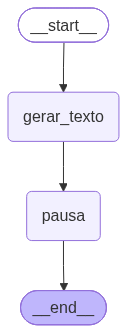

In [12]:
import re
class DynBPState(TypedDict, total=False):
    tema: str
    texto: str
    modo_debug: bool

PALAVRAS_CHAVE = {"Startups", "IA", "Langgraph"}



def node_gerar_texto(state: DynBPState) -> DynBPState:
    tema = state.get("tema", "tema")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR."),
        HumanMessage(content=f"Escreva um texto com poucas palavras sobre os temas em bulletpoints {tema}.")
    ])
    return {"texto": resp.content}
def node_pausa_condicional(state: DynBPState) -> DynBPState:
    texto = state.get("texto", "")

    if state.get("modo_debug"):
        interrupt({
            "motivo": "modo_debug ligado",
            "amostra_texto": texto[:250],
        })
        return {}

    palavras = set(re.findall(r"\w+", texto.casefold()))
    encontradas = sorted(PALAVRAS_CHAVE & palavras)

    if encontradas:
        interrupt({
            "motivo": "palavras-chave detectadas",
            "palavras_encontradas": encontradas,
            "amostra_texto": texto[:250],
        })

    return {}
dyn_builder = StateGraph(DynBPState)
dyn_builder.add_node("gerar_texto", node_gerar_texto)
dyn_builder.add_node("pausa", node_pausa_condicional)
dyn_builder.add_edge(START, "gerar_texto")
dyn_builder.add_edge("gerar_texto", "pausa")
dyn_builder.add_edge("pausa", END)

dyn_checkpointer = MemorySaver()
dyn_graph = dyn_builder.compile(checkpointer=dyn_checkpointer)
dyn_graph

In [13]:
cfg = {"configurable": {"thread_id": "dyn-01"}}
res = dyn_graph.invoke({"tema": "Startups, IA, Langgraph", "modo_debug": True}, config=cfg)

resb = dyn_graph.invoke(Command(resume="seguir"), config=cfg)
print("Concluiu. Texto (amostra):")
print(resb["texto"][:450], "...")

Concluiu. Texto (amostra):
- **Startups**: inovação ágil, modelo escalável, cultura de experimentação.  
- **IA**: aprendizado automático, automação inteligente, decisões baseadas em dados.  
- **Langgraph**: grafos de linguagem, fluxo de informações, integração semântica. ...


In [41]:
print("Concluiu. Texto completo:")
print(res2b["texto"])

Concluiu. Texto completo:
**Startups, IA e LangGraph – pontos‑chave**

- **Cenário de startups de IA no Brasil**
  - Crescimento acelerado: mais de 300 novas startups de IA surgiram nos últimos 3 anos.
  - Principais áreas de atuação: fintech, healthtech, agritech, edtech e e‑commerce.
  - Fonte de financiamento: fundos de venture capital (ex.: Kaszek, Monashees) e programas de aceleração (Google for Startups, NVIDIA Inception).

- **Por que a IA é um diferencial competitivo para startups**
  - **Automação inteligente** – reduz custos operacionais e libera equipe para tarefas de maior valor.
  - **Personalização em escala** – recomendações, chatbots e assistentes virtuais que aumentam engajamento e retenção.
  - **Insights baseados em dados** – modelos preditivos que otimizam pricing, churn e forecasting.
  - **Barreira de entrada** – propriedade intelectual de modelos ou pipelines de dados cria moat contra concorrentes.

- **Desafios comuns ao adotar IA em startups**
  - **Escassez de